# Visualize the released MCLR weights

Compare three experiments in **separate grids**:

1. **CFG sweep:** increase guidance on the same frozen REPA base model.
2. **MCLR alone:** follow fine-tuning without additional DSM or KL terms.
3. **MCLR + KL:** follow fine-tuning with trust-region regularization (coefficient 1).

In every grid, **one row = one fixed seed and ImageNet class**. Read from **left to
right** to see increasing CFG scales or training iterations. All three grids use the
same initial noise and classes, and start with the exact same base-model images.

Run the cells from top to bottom from the repository root with a CUDA GPU.
Place the nine released `.pt` files in `mclr_weights/`.
The weights are available on [Hugging Face](https://huggingface.co/SeanLi0210/MCLR-SiT-XL-2-REPA/tree/main/weights).
The VAE is downloaded and cached by Diffusers on first use; no training data or evaluation
reference files are needed.

The default eight examples generate **104 unique images** (13 settings x 8 examples).
The base images are reused across the three grids. Sampling can take several minutes.

## 1. Imports

Use the repository's SiT model and Euler sampler directly.

In [7]:
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from diffusers import AutoencoderKL
from models.sit import SiT_models
from samplers import euler_sampler

assert torch.cuda.is_available(), "Select a notebook environment with a CUDA GPU."
device = torch.device("cuda:0")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

## 2. Shared settings and examples

Each `(seed, class)` pair defines one row in **every** experiment. The defaults include
eight pairs. Add more pairs or remove entries to control the number of examples.
ImageNet class IDs range from 0 to 999.

All experiments use **50-step Euler ODE sampling**. The two fine-tuning experiments
use **CFG = 1** (no guidance). The CFG sweep changes guidance only at sampling time.
`VAE_ID` can also point to a local VAE directory for offline use.

In [ ]:
WEIGHTS_DIR = Path("weights")
VAE_ID = "stabilityai/sd-vae-ft-ema"
NUM_STEPS = 50

# Each entry is (seed, ImageNet class ID), in display order.
EXAMPLES = [
    (0, 207),  # golden retriever
    (1, 281),  # tabby cat
    (2, 949),  # strawberry
    (3, 569),  # garbage truck
    (4, 88),   # macaw
    (5, 323),  # monarch butterfly
    (6, 973),  # coral reef
    (7, 980),  # volcano
]

assert EXAMPLES, "Choose at least one example."
assert all(0 <= class_id < 1000 for seed, class_id in EXAMPLES)
assert all(0 <= seed < 2**63 for seed, class_id in EXAMPLES)
assert NUM_STEPS >= 2

## 3. Fixed noise, model, and VAE

Each seed creates its own initial noise on the CPU. These inputs are reused without
modification in all three experiments. We keep just one SiT model on the GPU and replace
its weights when changing checkpoints.

The released base checkpoint is a raw state dictionary. Fine-tuned checkpoints use the
**`model`** field, rather than EMA weights. The name `sd-vae-ft-ema` below refers only
to the VAE variant used to decode latents into 256 x 256 images.

In [9]:
noise = torch.stack([
    torch.randn(4, 32, 32, generator=torch.Generator().manual_seed(seed))
    for seed, class_id in EXAMPLES
]).to(device)
labels = torch.tensor([class_id for seed, class_id in EXAMPLES], device=device)

model = SiT_models["SiT-XL/2"](
    input_size=32,
    num_classes=1000,
    use_cfg=True,
    z_dims=[768],
    encoder_depth=8,
    fused_attn=False,
    qk_norm=False,
).to(device).eval().requires_grad_(False)

vae = AutoencoderKL.from_pretrained(VAE_ID)
vae = vae.to(device).eval().requires_grad_(False)

## 4. Two small helpers

`sample_checkpoint` loads a weight file and generates one image per example.
It samples **one image at a time** to limit GPU memory use.

`show_comparison` places settings in columns and seed/class pairs in rows.
There is no disk cache: rerunning a sampling cell generates its images again.

In [10]:
@torch.inference_mode()
def sample_checkpoint(filename, cfg_scale=1.0):
    print(f"Sampling {filename}, CFG={cfg_scale:g} ...", flush=True)
    checkpoint = torch.load(
        WEIGHTS_DIR / filename, map_location="cpu", mmap=True, weights_only=True
    )
    state_dict = checkpoint["model"] if "model" in checkpoint else checkpoint
    model.load_state_dict(state_dict, strict=True)
    del checkpoint, state_dict

    images = []
    for i in range(len(EXAMPLES)):
        latents = euler_sampler(
            model, noise[i:i + 1], labels[i:i + 1],
            num_steps=NUM_STEPS, cfg_scale=cfg_scale,
            heun=False, guidance_low=0.0, guidance_high=1.0,
            path_type="linear",
        ).float()
        pixels = vae.decode(latents / 0.18215).sample
        image = ((pixels[0] + 1) / 2).clamp(0, 1)
        images.append(image.permute(1, 2, 0).cpu().numpy())
    return images


def show_comparison(columns, titles, run_name):
    fig, axes = plt.subplots(
        len(EXAMPLES), len(columns),
        figsize=(2.6 * len(columns), 2.6 * len(EXAMPLES)), squeeze=False,
    )
    for col, images in enumerate(columns):
        for row, (seed, class_id) in enumerate(EXAMPLES):
            ax = axes[row, col]
            ax.imshow(images[row])
            ax.set_xticks([])
            ax.set_yticks([])
            if row == 0:
                ax.set_title(titles[col])
            if col == 0:
                ax.set_ylabel(f"Seed {seed}\nClass {class_id}", rotation=0,
                              ha="right", va="center", labelpad=15)
    fig.suptitle(f"{run_name} | {NUM_STEPS}-step Euler ODE", y=1.01)
    fig.tight_layout()
    plt.show()
    return fig

## 5. Base images shared by all experiments

Generate the unguided REPA base images once. Every experiment below reuses this list
as its first column, so the baseline is identical in all three figures.

In [11]:
base_images = sample_checkpoint("base_repa.pt", cfg_scale=1.0)

Sampling base_repa.pt, CFG=1 ...


## Experiment 1: CFG sweep on the REPA base model

**What changes:** CFG scale at sampling time. **What stays fixed:** the base-model
weights, initial noise, class labels, and sampling steps. There is no fine-tuning.

Read left to right: **CFG = 1.0, 1.2, 1.4, 1.6, 2.0**. CFG = 1.0 means no guidance.
Among the evaluated scales, the best FID is **2.08756 at CFG = 1.4**; the best
FD DINOv2 is **50.2323 at CFG = 2.0**.

Sampling base_repa.pt, CFG=1.2 ...
Sampling base_repa.pt, CFG=1.4 ...
Sampling base_repa.pt, CFG=1.6 ...
Sampling base_repa.pt, CFG=2 ...


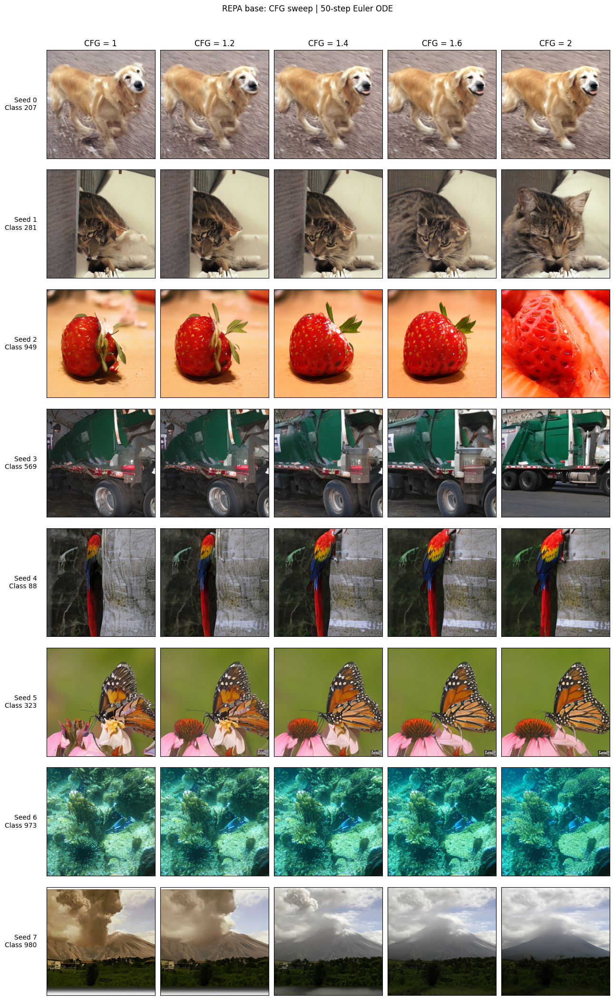

In [12]:
CFG_SCALES = [1.0, 1.2, 1.4, 1.6, 2.0]

cfg_columns = []
for scale in CFG_SCALES:
    images = base_images if scale == 1.0 else sample_checkpoint("base_repa.pt", scale)
    cfg_columns.append(images)

fig_cfg = show_comparison(
    cfg_columns,
    [f"CFG = {scale:g}" for scale in CFG_SCALES],
    "REPA base: CFG sweep",
)

## Experiment 2: MCLR alone

**What changes:** model weights at successive fine-tuning iterations of the same run.
This run uses the MCLR objective **without additional DSM or KL regularization**.
All columns use **CFG = 1**, the same noise, and the same class labels.

Read left to right: **base (0), 150, 250, 350, 550 iterations**.
The best observed FID is **2.40690 at iteration 250**; the best observed
FD DINOv2 is **45.9626 at iteration 550**.

Sampling mclr_0000150.pt, CFG=1 ...
Sampling mclr_fid_best_0000250.pt, CFG=1 ...
Sampling mclr_0000350.pt, CFG=1 ...
Sampling mclr_dino_best_0000550.pt, CFG=1 ...


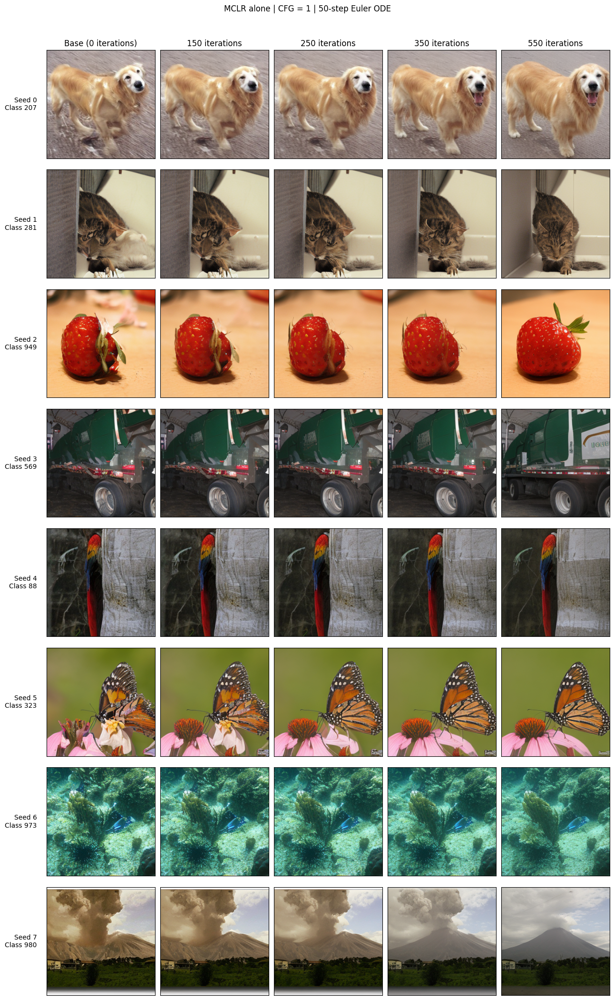

In [13]:
MCLR_CHECKPOINTS = [
    (0, "base_repa.pt"),
    (150, "mclr_0000150.pt"),
    (250, "mclr_fid_best_0000250.pt"),
    (350, "mclr_0000350.pt"),
    (550, "mclr_dino_best_0000550.pt"),
]

mclr_columns = []
for step, filename in MCLR_CHECKPOINTS:
    images = base_images if step == 0 else sample_checkpoint(filename, cfg_scale=1.0)
    mclr_columns.append(images)

fig_mclr = show_comparison(
    mclr_columns,
    ["Base (0 iterations)" if step == 0 else f"{step} iterations"
     for step, filename in MCLR_CHECKPOINTS],
    "MCLR alone | CFG = 1",
)

## Experiment 3: MCLR + KL (trust-region regularization)

**What changes:** model weights at successive fine-tuning iterations of a separate run.
This run adds a **trust-region penalty with coefficient 1** against the frozen base
model, corresponding to the paper's KL-regularized setting. All columns use **CFG = 1**,
the same noise, and the same class labels.

Read left to right: **base (0), 150, 550, 1050, 1650 iterations**.
The best observed FID is **2.11113 at iteration 550**; the best observed
FD DINOv2 is **48.3722 at iteration 1650**.
The iteration values differ from Experiment 2; each grid labels its own checkpoints.

Sampling mclr_kl_0000150.pt, CFG=1 ...
Sampling mclr_kl_fid_best_0000550.pt, CFG=1 ...
Sampling mclr_kl_0001050.pt, CFG=1 ...
Sampling mclr_kl_dino_best_0001650.pt, CFG=1 ...


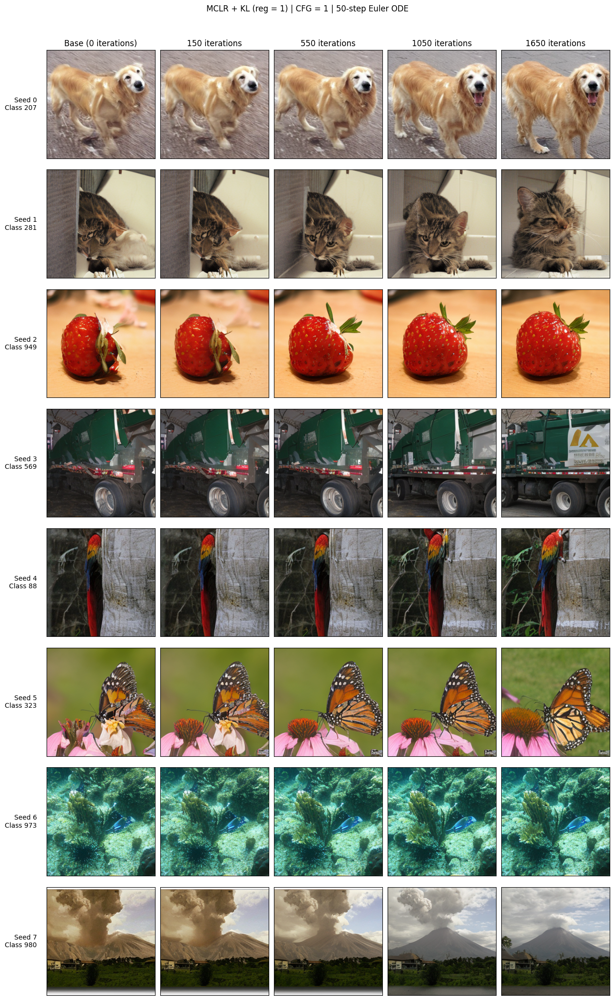

In [14]:
KL_CHECKPOINTS = [
    (0, "base_repa.pt"),
    (150, "mclr_kl_0000150.pt"),
    (550, "mclr_kl_fid_best_0000550.pt"),
    (1050, "mclr_kl_0001050.pt"),
    (1650, "mclr_kl_dino_best_0001650.pt"),
]

kl_columns = []
for step, filename in KL_CHECKPOINTS:
    images = base_images if step == 0 else sample_checkpoint(filename, cfg_scale=1.0)
    kl_columns.append(images)

fig_kl = show_comparison(
    kl_columns,
    ["Base (0 iterations)" if step == 0 else f"{step} iterations"
     for step, filename in KL_CHECKPOINTS],
    "MCLR + KL (reg = 1) | CFG = 1",
)

## Save the figures or try more examples

Each experiment has its own figure, which you can save separately:

```python
fig_cfg.savefig("repa_cfg_sweep.png", dpi=150, bbox_inches="tight")
fig_mclr.savefig("mclr_iterations.png", dpi=150, bbox_inches="tight")
fig_kl.savefig("mclr_kl_iterations.png", dpi=150, bbox_inches="tight")
```

Add `(seed, class_id)` pairs to `EXAMPLES` for more rows, then rerun from Section 2.
Edit the scales or checkpoint lists inside an experiment to change its columns.
After changing examples, regenerate the shared base images before running any experiment.

The quoted FID/FD values come from historical **50,000-image** evaluations.
These grids are qualitative examples and do not recalculate those metrics.